# Лабораторна робота №9
## Інтеграція навченої ML-моделі в інформаційну систему

**Мета:** виконати інтеграцію навченої моделі машинного навчання до складу інформаційної системи; дослідити збереження та завантаження моделі, доступ до неї через програмний API, оброблення вхідних запитів і формування прогнозу, а також часові характеристики inference.

## 1. Вибір і навчання моделі

Обрано модель з попередніх робіт - **Logistic Regression** для прогнозу відтоку клієнтів (`Churn`) на наборі Telco Customer Churn. У ЛР3 вона мала найкращий F1, а в ЛР8 виявилась найефективнішою: якість на рівні найкращих моделей і найшвидший прогноз, що важливо для сервісу. Модель навчається разом з попередньою обробкою в одному Pipeline.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import json
import joblib
from pathlib import Path
import warnings

warnings.filterwarnings("ignore", message=".*httpx.*")
pd.set_option("display.max_colwidth", None)

In [2]:
df = pd.read_csv("data/WA_Fn-UseC_-Telco-Customer-Churn.csv")
df = df.drop(columns=["customerID"])
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.drop_duplicates()
df["Churn"] = df["Churn"].map({"Yes": 1, "No": 0})

y = df["Churn"]
X = df.drop(columns=["Churn"])

numeric_columns = ["tenure", "MonthlyCharges", "TotalCharges"]
categorical_columns = list(X.select_dtypes(include="object").columns)

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Train:", X_train.shape, " Test:", X_test.shape)

Train: (5616, 19)  Test: (1405, 19)


In [3]:
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

preprocessor = ColumnTransformer([
    ("num", Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler())
    ]), numeric_columns),
    ("cat", Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ]), categorical_columns),
    ("senior", "passthrough", ["SeniorCitizen"])
])

model = Pipeline([
    ("prep", preprocessor),
    ("model", LogisticRegression(max_iter=1000, random_state=42))
])

start = time.time()
model.fit(X_train, y_train)
train_time = time.time() - start

test_pred = model.predict(X_test)
test_proba = model.predict_proba(X_test)[:, 1]

test_metrics = {
    "accuracy": round(accuracy_score(y_test, test_pred), 4),
    "precision": round(precision_score(y_test, test_pred), 4),
    "recall": round(recall_score(y_test, test_pred), 4),
    "f1": round(f1_score(y_test, test_pred), 4),
    "roc_auc": round(float(roc_auc_score(y_test, test_proba)), 4)
}

print("Час навчання, с:", round(train_time, 3))
print("Метрики на тестовій вибірці:", test_metrics)

Час навчання, с: 0.046
Метрики на тестовій вибірці: {'accuracy': 0.8028, 'precision': 0.661, 'recall': 0.5242, 'f1': 0.5847, 'roc_auc': 0.8403}


Pipeline складається з двох кроків. `prep` (ColumnTransformer): числові ознаки заповнюються медіаною і стандартизуються, категоріальні заповнюються найчастішим значенням і кодуються One-Hot, `SeniorCitizen` проходить без змін. `model` - Logistic Regression. Модель навчено на 5616 клієнтах за 0.05 с. На тестовій вибірці: Accuracy 0.803, Precision 0.661, Recall 0.524, F1 0.585, ROC-AUC 0.840 - це ті самі результати, що й у ЛР8, тобто модель відтворюється.

## 2-3. Збереження моделі разом з Pipeline

In [4]:
import sklearn

Path("model").mkdir(exist_ok=True)
model_path = Path("model/churn_pipeline.joblib")
joblib.dump(model, model_path)

model_info = {
    "model_name": "churn_logistic_regression",
    "model_version": "1.0",
    "trained_at": time.strftime("%Y-%m-%d %H:%M"),
    "dataset": "Telco Customer Churn (WA_Fn-UseC_-Telco-Customer-Churn.csv), train 80%",
    "train_size": len(X_train),
    "features": list(X.columns),
    "target": "Churn (1 - клієнт піде, 0 - залишиться)",
    "hyperparameters": {"C": 1.0, "max_iter": 1000, "solver": "lbfgs"},
    "test_metrics": test_metrics,
    "library_versions": {"scikit-learn": sklearn.__version__, "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__}
}

with open("model/model_info.json", "w", encoding="utf-8") as f:
    json.dump(model_info, f, ensure_ascii=False, indent=2)

print("Збережено:", model_path, "-", round(model_path.stat().st_size / 1024, 1), "КБ")
print("Збережено: model/model_info.json")
print("Кроки збереженого Pipeline:", [name for name, step in model.steps])

Збережено: model\churn_pipeline.joblib - 8.8 КБ
Збережено: model/model_info.json
Кроки збереженого Pipeline: ['prep', 'model']


**Серіалізація.** `joblib.dump` зберігає весь Pipeline у файл `model/churn_pipeline.joblib` (8.8 КБ): не лише коефіцієнти логістичної регресії, а й навчені медіани, середні та std скейлера, список категорій енкодера. Тому нові дані будуть оброблені точно так само, як під час навчання, і не потрібно окремо зберігати скейлер чи енкодер.

**Метадані.** Поруч збережено `model/model_info.json`: назва і версія моделі, дата навчання, датасет, список ознак, гіперпараметри, метрики на тесті і версії бібліотек. Це потрібно для контролю версій: якщо модель оновлять, буде видно, яка версія працює в сервісі і з якими бібліотеками її можна завантажити.

## 4. Завантаження моделі без повторного навчання

In [5]:
original_predictions = model.predict(X_test.head(5))
original_proba = model.predict_proba(X_test.head(5))[:, 1]

del model

start = time.perf_counter()
loaded_model = joblib.load("model/churn_pipeline.joblib")
load_ms = (time.perf_counter() - start) * 1000

print("Модель завантажено за", round(load_ms, 2), "мс")
print("Тип:", type(loaded_model).__name__)
print("Вхідні ознаки:", len(loaded_model.feature_names_in_))

Модель завантажено за 2.15 мс
Тип: Pipeline
Вхідні ознаки: 19


## 5. Перевірка завантаженої моделі

In [6]:
sample = X_test.head(5)
predictions = loaded_model.predict(sample)
probabilities = loaded_model.predict_proba(sample)[:, 1]

print("Прогнози збігаються з оригінальною моделлю:", np.array_equal(original_predictions, predictions))
print("Ймовірності збігаються:", np.allclose(original_proba, probabilities))

pd.DataFrame({
    "Фактичний клас": y_test.loc[sample.index].to_numpy(),
    "Прогноз": predictions,
    "Ймовірність відтоку": probabilities.round(3)
}, index=sample.index)

Прогнози збігаються з оригінальною моделлю: True
Ймовірності збігаються: True


,Фактичний клас,Прогноз,Ймовірність відтоку
5627,0,1,0.758
6126,1,1,0.617
2361,1,0,0.285
2201,0,0,0.049
832,0,0,0.009


Змінну `model` видалено з пам'яті, а модель завантажено з файлу через `joblib.load` - **без повторного навчання**. Завантаження зайняло близько **2 мс**. Завантажений об'єкт - той самий Pipeline з 19 вхідними ознаками. Прогнози і ймовірності для 5 тестових клієнтів повністю збігаються з прогнозами оригінальної моделі (`True`). Наприклад, перший клієнт отримав ймовірність відтоку 0.758 і прогноз «піде».

## 6-11. Програмний API на FastAPI

In [7]:
%%writefile app.py
from pathlib import Path
from typing import Literal, Optional
import json
import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, Field, ConfigDict, model_validator

MODEL_DIR = Path(__file__).parent / "model"
model = joblib.load(MODEL_DIR / "churn_pipeline.joblib")
model_info = json.loads((MODEL_DIR / "model_info.json").read_text(encoding="utf-8"))

app = FastAPI(title="Telco Churn Prediction API", version=model_info["model_version"])

YesNo = Literal["Yes", "No"]
InternetOption = Literal["Yes", "No", "No internet service"]


class Customer(BaseModel):
    model_config = ConfigDict(extra="forbid", strict=True)

    gender: Literal["Female", "Male"]
    SeniorCitizen: Literal[0, 1]
    Partner: YesNo
    Dependents: YesNo
    tenure: int = Field(ge=0, le=100)
    PhoneService: YesNo
    MultipleLines: Literal["Yes", "No", "No phone service"]
    InternetService: Literal["DSL", "Fiber optic", "No"]
    OnlineSecurity: InternetOption
    OnlineBackup: InternetOption
    DeviceProtection: InternetOption
    TechSupport: InternetOption
    StreamingTV: InternetOption
    StreamingMovies: InternetOption
    Contract: Literal["Month-to-month", "One year", "Two year"]
    PaperlessBilling: YesNo
    PaymentMethod: Literal["Electronic check", "Mailed check",
                           "Bank transfer (automatic)", "Credit card (automatic)"]
    MonthlyCharges: float = Field(ge=0, le=200)
    TotalCharges: Optional[float] = Field(default=None, ge=0)

    @model_validator(mode="after")
    def check_services(self):
        services = [self.OnlineSecurity, self.OnlineBackup, self.DeviceProtection,
                    self.TechSupport, self.StreamingTV, self.StreamingMovies]
        if self.InternetService == "No" and any(s != "No internet service" for s in services):
            raise ValueError("Без інтернету всі інтернет-послуги мають бути 'No internet service'")
        if self.InternetService != "No" and any(s == "No internet service" for s in services):
            raise ValueError("Є інтернет, тому значення 'No internet service' неприпустиме")
        if (self.PhoneService == "No") != (self.MultipleLines == "No phone service"):
            raise ValueError("MultipleLines = 'No phone service' тільки якщо PhoneService = 'No'")
        return self


def postprocess(probability):
    if probability < 0.3:
        risk = "низький"
    elif probability < 0.6:
        risk = "середній"
    else:
        risk = "високий"
    churn_class = int(probability >= 0.5)
    return {
        "churn": "Yes" if churn_class == 1 else "No",
        "churn_class": churn_class,
        "probability": round(float(probability), 4),
        "risk": risk,
        "model_version": model_info["model_version"]
    }


@app.get("/health")
def health():
    return {"status": "ok", "model": model_info["model_name"], "model_version": model_info["model_version"]}


@app.post("/predict")
def predict(customer: Customer):
    X = pd.DataFrame([customer.model_dump()])
    probability = model.predict_proba(X)[0, 1]
    return postprocess(probability)


@app.post("/predict_batch")
def predict_batch(customers: list[Customer]):
    if not 1 <= len(customers) <= 1000:
        raise HTTPException(status_code=422, detail="Кількість клієнтів має бути від 1 до 1000")
    X = pd.DataFrame([c.model_dump() for c in customers])
    probabilities = model.predict_proba(X)[:, 1]
    return {"count": len(customers), "predictions": [postprocess(p) for p in probabilities]}

Writing app.py


Команда `%%writefile app.py` записує код сервісу в окремий файл, бо API запускається як окрема програма. Це єдиний `.py` файл у проєкті: без нього сервіс не запустити. Клас і функції в ньому обов'язкові, бо так влаштовані FastAPI і pydantic.

**Структура сервісу:**
- **Завантаження моделі** відбувається **один раз** при старті сервісу, а не при кожному запиті.
- **Схема вхідного запиту** `Customer` описує всі 19 ознак клієнта. Вона ж виконує **валідацію**:
  - `extra="forbid"` - зайві поля заборонені;
  - `strict=True` - типи не перетворюються автоматично (рядок "5" не стане числом);
  - `Literal[...]` - допустимі значення для кожної категоріальної ознаки;
  - `Field(ge=..., le=...)` - допустимі діапазони чисел (`tenure` 0-100, `MonthlyCharges` 0-200, `TotalCharges` >= 0);
  - `TotalCharges` необов'язкове, бо в даних бувають пропуски, і їх заповнить імпутер у Pipeline;
  - `model_validator` перевіряє логічну узгодженість: без інтернету всі інтернет-послуги мають бути «No internet service», а «No phone service» допустиме тільки без телефону.
- **Ендпоїнти:**
  - `GET /health` - перевірка, що сервіс працює, і версія моделі;
  - `POST /predict` - прогноз для одного клієнта;
  - `POST /predict_batch` - прогноз для списку від 1 до 1000 клієнтів.
- **Ланцюжок оброблення запиту:** Request (JSON) -> **Validation** (pydantic, при помилці одразу HTTP 422) -> **Preprocessing** (дані перетворюються в DataFrame, далі їх обробляє ColumnTransformer усередині Pipeline) -> **Inference** (`predict_proba`) -> **Postprocessing** (функція `postprocess`) -> Response (JSON).
- **Формат відповіді:** `churn` ("Yes"/"No"), `churn_class` (1/0), `probability` - ймовірність відтоку, округлена до 4 знаків, `risk` - рівень ризику (низький < 0.3, середній < 0.6, високий) і `model_version`.

## 12. Перевірка API на коректних запитах

In [8]:
from fastapi.testclient import TestClient
from app import app

client = TestClient(app)

print("GET /health:", client.get("/health").json())

samples = X_test.dropna().head(3)
direct_pred = loaded_model.predict(samples)
direct_proba = loaded_model.predict_proba(samples)[:, 1]

for i, data in enumerate(samples.to_dict("records")):
    response = client.post("/predict", json=data)
    result = response.json()
    same = result["churn_class"] == direct_pred[i] and abs(result["probability"] - direct_proba[i]) < 0.0001
    print("Запит", i + 1, "- HTTP", response.status_code, result, "| збігається з моделлю:", same)

GET /health: {'status': 'ok', 'model': 'churn_logistic_regression', 'model_version': '1.0'}
Запит 1 - HTTP 200 {'churn': 'Yes', 'churn_class': 1, 'probability': 0.7582, 'risk': 'високий', 'model_version': '1.0'} | збігається з моделлю: True
Запит 2 - HTTP 200 {'churn': 'Yes', 'churn_class': 1, 'probability': 0.617, 'risk': 'високий', 'model_version': '1.0'} | збігається з моделлю: True
Запит 3 - HTTP 200 {'churn': 'No', 'churn_class': 0, 'probability': 0.2845, 'risk': 'низький', 'model_version': '1.0'} | збігається з моделлю: True


In [9]:
print("Приклад JSON-запиту:")
print(json.dumps(samples.to_dict("records")[0], ensure_ascii=False, indent=2))

Приклад JSON-запиту:
{
  "gender": "Male",
  "SeniorCitizen": 1,
  "Partner": "Yes",
  "Dependents": "No",
  "tenure": 7,
  "PhoneService": "Yes",
  "MultipleLines": "Yes",
  "InternetService": "Fiber optic",
  "OnlineSecurity": "No",
  "OnlineBackup": "No",
  "DeviceProtection": "No",
  "TechSupport": "No",
  "StreamingTV": "No",
  "StreamingMovies": "No",
  "Contract": "Month-to-month",
  "PaperlessBilling": "Yes",
  "PaymentMethod": "Electronic check",
  "MonthlyCharges": 74.85,
  "TotalCharges": 485.25
}


API перевірено через `TestClient`, тобто без запуску окремого сервера. `GET /health` повертає статус «ok» і версію моделі 1.0. Для трьох тестових клієнтів API повернуло HTTP 200, і результати **повністю збігаються** з прямим викликом моделі: клас і ймовірність (0.7582, 0.617, 0.2845) ті самі. Отже, валідація і передавання даних через JSON не змінюють прогноз. Нижче показано приклад JSON-запиту з усіма 19 полями.

## 13. Перевірка API на некоректних запитах

In [10]:
valid = samples.to_dict("records")[0]

invalid_requests = {
    "Відсутнє поле Contract": {k: v for k, v in valid.items() if k != "Contract"},
    "Неправильний тип tenure": {**valid, "tenure": "п'ять"},
    "Від'ємне MonthlyCharges": {**valid, "MonthlyCharges": -10.0},
    "Неприпустима категорія": {**valid, "PaymentMethod": "Cash"},
    "Зайве поле": {**valid, "customerID": "1234-ABCD"},
    "Суперечність послуг": {**valid, "InternetService": "No"}
}

invalid_rows = []
for name, payload in invalid_requests.items():
    response = client.post("/predict", json=payload)
    invalid_rows.append({
        "Перевірка": name,
        "HTTP": response.status_code,
        "Повідомлення": response.json()["detail"][0]["msg"]
    })

invalid_table = pd.DataFrame(invalid_rows)
invalid_table

,Перевірка,HTTP,Повідомлення
0,Відсутнє поле Contract,422,Field required
1,Неправильний тип tenure,422,Input should be a valid integer
2,Від'ємне MonthlyCharges,422,Input should be greater than or equal to 0
3,Неприпустима категорія,422,"Input should be 'Electronic check', 'Mailed check', 'Bank transfer (automatic)' or 'Credit card (automatic)'"
4,Зайве поле,422,Extra inputs are not permitted
5,Суперечність послуг,422,"Value error, Без інтернету всі інтернет-послуги мають бути 'No internet service'"


Шість некоректних запитів, і на всі API відповіло **HTTP 422 (Unprocessable Content)**, не передаючи дані моделі:
- **відсутнє обов'язкове поле** `Contract` -> «Field required»;
- **неправильний тип** (`tenure` = "п'ять") -> «Input should be a valid integer»;
- **недопустиме значення** (`MonthlyCharges` = -10) -> «Input should be greater than or equal to 0»;
- **неприпустима категорія** (`PaymentMethod` = "Cash") -> перелік допустимих способів оплати;
- **зайве поле** (`customerID`) -> «Extra inputs are not permitted». Так перевіряється відповідність структури ознак вимогам моделі;
- **логічна суперечність** (немає інтернету, але є інтернет-послуги) -> власне повідомлення з `model_validator`.

Без такої перевірки модель або впала б з помилкою, або, що гірше, мовчки дала б неправильний прогноз (наприклад, невідому категорію енкодер закодував би нулями).

## 14-17. Час завантаження та inference

In [11]:
load_times = []
for _ in range(10):
    start = time.perf_counter()
    joblib.load("model/churn_pipeline.joblib")
    load_times.append((time.perf_counter() - start) * 1000)

benchmark_model = joblib.load("model/churn_pipeline.joblib")
one_customer = pd.DataFrame([valid])

start = time.perf_counter()
benchmark_model.predict_proba(one_customer)
first_inference_ms = (time.perf_counter() - start) * 1000

inference_times = []
for _ in range(100):
    start = time.perf_counter()
    benchmark_model.predict_proba(one_customer)
    inference_times.append((time.perf_counter() - start) * 1000)

print("Час завантаження моделі (перший), мс:", round(load_ms, 3))
print("Час завантаження (середнє з 10), мс:", round(np.mean(load_times), 3))
print("Перший inference, мс:", round(first_inference_ms, 3))
print("Inference за 100 прогнозами, мс: min", round(min(inference_times), 3),
      " max", round(max(inference_times), 3),
      " mean", round(np.mean(inference_times), 3),
      " median", round(np.median(inference_times), 3))

Час завантаження моделі (перший), мс: 2.154
Час завантаження (середнє з 10), мс: 1.9
Перший inference, мс: 5.388
Inference за 100 прогнозами, мс: min 3.636  max 5.291  mean 4.037  median 3.931


- **Завантаження моделі** займає близько **2 мс** (перше 2.15 мс, середнє з 10 завантажень 1.90 мс). Модель маленька (8.8 КБ), тому завантажується майже миттєво.
- **Перший inference** триває **5.39 мс**, а **наступні 100** у середньому **4.04 мс** (min 3.64, max 5.29, медіана 3.93). Перший прогноз повільніший приблизно на третину, бо при першому виклику Python і бібліотеки ще ініціалізують внутрішні структури і кеші.
- Майже весь час прогнозу для одного клієнта йде не на саму логістичну регресію (одне множення векторів), а на **попередню обробку** в Pipeline: створення DataFrame, імпутери, скейлер і One-Hot енкодер.

## 18. Час оброблення API-запиту на реальному сервері

In [12]:
import subprocess
import sys
import httpx

server = subprocess.Popen(
    [sys.executable, "-m", "uvicorn", "app:app", "--host", "127.0.0.1", "--port", "8010"],
    stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL
)

api = httpx.Client(base_url="http://127.0.0.1:8010", timeout=30)

start_service = time.perf_counter()
for _ in range(200):
    try:
        if api.get("/health").status_code == 200:
            break
    except httpx.RequestError:
        time.sleep(0.1)
startup_s = time.perf_counter() - start_service

start = time.perf_counter()
response = api.post("/predict", json=valid)
first_api_ms = (time.perf_counter() - start) * 1000

api_times = []
start_total = time.perf_counter()
for _ in range(100):
    start = time.perf_counter()
    response = api.post("/predict", json=valid)
    api_times.append((time.perf_counter() - start) * 1000)
total_api_s = time.perf_counter() - start_total

api_throughput = 100 / total_api_s

print("Сервер готовий через, с:", round(startup_s, 2))
print("Відповідь сервера:", response.json())
print("Перший API-запит, мс:", round(first_api_ms, 3))
print("API-запит за 100 запитами, мс: min", round(min(api_times), 3),
      " max", round(max(api_times), 3), " mean", round(np.mean(api_times), 3))
print("Накладні витрати API (mean API - mean inference), мс:", round(np.mean(api_times) - np.mean(inference_times), 3))
print("Throughput через API, запитів/с:", round(api_throughput, 1))

Сервер готовий через, с: 1.53
Відповідь сервера: {'churn': 'Yes', 'churn_class': 1, 'probability': 0.7582, 'risk': 'високий', 'model_version': '1.0'}
Перший API-запит, мс: 8.831
API-запит за 100 запитами, мс: min 5.856  max 8.081  mean 6.629
Накладні витрати API (mean API - mean inference), мс: 2.592
Throughput через API, запитів/с: 150.8


Сервіс запущено як справжній HTTP-сервер (`uvicorn`) в окремому процесі на порту 8010, а запити відправляються через `httpx`, як це робила б інша інформаційна система.
- **Холодний старт сервісу** (запуск Python, імпорт бібліотек, завантаження моделі) займає близько **1.5 с**.
- **Перший API-запит** триває **8.83 мс**, **наступні 100** у середньому **6.63 мс** (min 5.86, max 8.08).
- **Порівняння з прямим inference:** API-запит у середньому на **2.6 мс довший** (6.63 проти 4.04 мс). Ці 2.6 мс - накладні витрати інформаційної системи: передавання HTTP-запиту, розбір JSON, валідація pydantic, формування відповіді. Тобто сама модель займає близько 60% часу запиту.
- **Throughput** при послідовних запитах по одному клієнту - близько **151 запиту за секунду**.

## 19-20. Batch inference і throughput

In [13]:
batch_rows = []
pool = X_test.dropna()

for n in [1, 10, 50, 100, 500, 1000]:
    batch = pool.head(n)
    payload = batch.to_dict("records")

    direct_times = []
    api_batch_times = []
    for _ in range(10):
        start = time.perf_counter()
        benchmark_model.predict_proba(batch)
        direct_times.append((time.perf_counter() - start) * 1000)

        start = time.perf_counter()
        response = api.post("/predict_batch", json=payload)
        api_batch_times.append((time.perf_counter() - start) * 1000)

    batch_rows.append({
        "Batch": n,
        "Модель, мс": np.mean(direct_times),
        "Модель на 1 об'єкт, мс": np.mean(direct_times) / n,
        "API, мс": np.mean(api_batch_times),
        "API на 1 об'єкт, мс": np.mean(api_batch_times) / n,
        "Throughput модель, прогнозів/с": n * 1000 / np.mean(direct_times),
        "Throughput API, прогнозів/с": n * 1000 / np.mean(api_batch_times)
    })

server.terminate()

batch_table = pd.DataFrame(batch_rows)
batch_table.round(3)

,Batch,"Модель, мс","Модель на 1 об'єкт, мс","API, мс","API на 1 об'єкт, мс","Throughput модель, прогнозів/с","Throughput API, прогнозів/с"
0,1,4.661,4.661,7.010,7.010,214.566,142.650
1,10,4.700,0.470,7.174,0.717,2127.537,1393.868
2,50,5.800,0.116,10.063,0.201,8621.240,4968.663
3,100,5.124,0.051,9.811,0.098,19514.708,10193.140
4,500,6.399,0.013,20.274,0.041,78136.110,24662.567
5,1000,7.310,0.007,35.218,0.035,136794.976,28394.974


Для кожного розміру batch (1, 10, 50, 100, 500, 1000 клієнтів) зроблено по 10 вимірювань: напряму через модель і через `/predict_batch`.
- **Напряму через модель** загальний час майже не росте: 4.7 мс для 1 клієнта і лише 7.3 мс для 1000. Тому час на одного клієнта падає з 4.66 мс до **0.007 мс**, а throughput росте з 215 до **136 795 прогнозів/с**. Майже весь час іде на «фіксовані» витрати (виклик Pipeline, створення DataFrame), а обчислення для кожного додаткового рядка дуже дешеві.
- **Через API** batch теж різко підвищує ефективність: 1000 клієнтів обробляються за 35 мс, тобто 0.035 мс на клієнта і близько **28 400 прогнозів/с** проти 151 при запитах по одному. Але тут загальний час росте помітніше (з 7 до 35 мс), бо JSON-розбір і валідація pydantic виконуються для кожного клієнта окремо.
- **Мінус batch:** відповідь на весь пакет приходить лише після обробки всіх об'єктів, тому затримка окремого запиту зростає (35 мс замість 7 мс), і потрібно більше пам'яті.

## 21. Підсумкова таблиця часових характеристик

In [14]:
timing_table = pd.DataFrame({
    "Показник": [
        "Час завантаження моделі, мс",
        "Перший inference, мс",
        "Min inference, мс",
        "Max inference, мс",
        "Середній inference, мс",
        "Перший API-запит, мс",
        "Середній API-запит, мс",
        "Throughput (по одному через API), прогнозів/с",
        "Throughput (batch 1000 через API), прогнозів/с"
    ],
    "Значення": [
        load_ms,
        first_inference_ms,
        min(inference_times),
        max(inference_times),
        np.mean(inference_times),
        first_api_ms,
        np.mean(api_times),
        api_throughput,
        batch_table["Throughput API, прогнозів/с"].iloc[-1]
    ]
})
timing_table.round(3)

,Показник,Значення
0,"Час завантаження моделі, мс",2.154
1,"Перший inference, мс",5.388
2,"Min inference, мс",3.636
3,"Max inference, мс",5.291
4,"Середній inference, мс",4.037
5,"Перший API-запит, мс",8.831
6,"Середній API-запит, мс",6.629
7,"Throughput (по одному через API), прогнозів/с",150.800
8,"Throughput (batch 1000 через API), прогнозів/с",28394.974


## 22. Графічне представлення часових характеристик

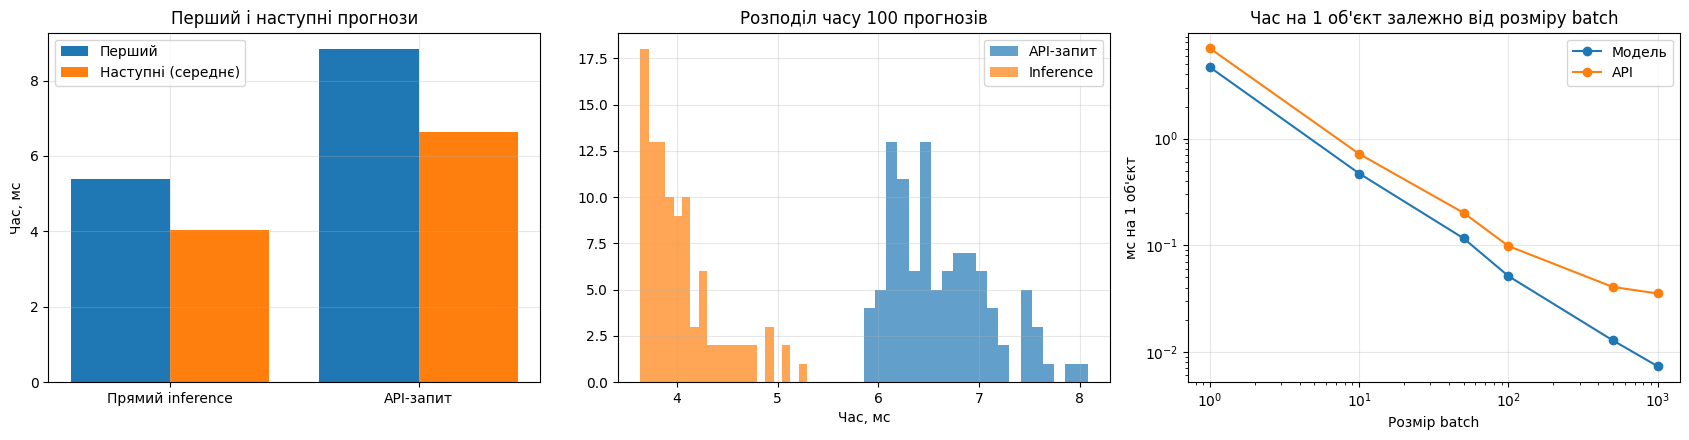

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))

x = np.arange(2)
axes[0].bar(x - 0.2, [first_inference_ms, first_api_ms], width=0.4, label="Перший")
axes[0].bar(x + 0.2, [np.mean(inference_times), np.mean(api_times)], width=0.4, label="Наступні (середнє)")
axes[0].set_xticks(x)
axes[0].set_xticklabels(["Прямий inference", "API-запит"])
axes[0].set_title("Перший і наступні прогнози")
axes[0].set_ylabel("Час, мс")
axes[0].legend()

axes[1].hist(api_times, bins=20, alpha=0.7, label="API-запит")
axes[1].hist(inference_times, bins=20, alpha=0.7, label="Inference")
axes[1].set_title("Розподіл часу 100 прогнозів")
axes[1].set_xlabel("Час, мс")
axes[1].legend()

axes[2].plot(batch_table["Batch"], batch_table["Модель на 1 об'єкт, мс"], marker="o", label="Модель")
axes[2].plot(batch_table["Batch"], batch_table["API на 1 об'єкт, мс"], marker="o", label="API")
axes[2].set_xscale("log")
axes[2].set_yscale("log")
axes[2].set_title("Час на 1 об'єкт залежно від розміру batch")
axes[2].set_xlabel("Розмір batch")
axes[2].set_ylabel("мс на 1 об'єкт")
axes[2].legend()

for ax in axes:
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

- **Лівий графік:** перший прогноз повільніший за наступні і для прямого inference (5.4 проти 4.0 мс), і для API (8.8 проти 6.6 мс), а API завжди повільніший за чистий inference.
- **Середній графік:** розподіл часу 100 прогнозів. Inference зосереджений біля 3.6-4.5 мс, API-запити біля 6-7 мс, і дві групи не перетинаються. Різниця між ними - це стабільні накладні витрати HTTP і валідації.
- **Правий графік** (обидві осі в логарифмічній шкалі): час на один об'єкт швидко падає зі збільшенням batch. Для моделі майже пропорційно розміру пакета, для API повільніше, бо валідація кожного об'єкта займає свій час.

## 23. Контейнеризація

Контейнеризація в завданні виконується «за бажанням». На комп'ютері, де виконувалась робота, Docker не встановлений, тому сервіс у контейнері не запускався. Для контейнеризації достатньо було б такого `Dockerfile` у папці `lab9`:

```
FROM python:3.13-slim
WORKDIR /app
RUN pip install --no-cache-dir fastapi uvicorn pandas scikit-learn joblib
COPY app.py .
COPY model/ model/
EXPOSE 8000
CMD ["uvicorn", "app:app", "--host", "0.0.0.0", "--port", "8000"]
```

Образ збирається командою `docker build -t churn-api .`, а запускається `docker run -p 8000:8000 churn-api`. Контейнер містить код сервісу, збережену модель і всі бібліотеки потрібних версій, тому сервіс однаково працюватиме на будь-якому комп'ютері чи сервері, і його можна масштабувати, запускаючи кілька копій.

## 24. Висновки

- **Особливості інтеграції.** Навчену модель збережено разом з усією попередньою обробкою як один Pipeline (`joblib`, 8.8 КБ) і окремо метадані (`model_info.json`). Модель завантажується за 2 мс без повторного навчання і дає ті самі прогнози, що й оригінальна. Сервіс завантажує модель один раз при старті, а не при кожному запиті.
- **Організація API.** Сервіс на FastAPI має три ендпоїнти (`/health`, `/predict`, `/predict_batch`) і повний ланцюжок Validation -> Preprocessing -> Inference -> Postprocessing. Прогнози через API повністю збігаються з прямим викликом моделі. Валідація pydantic відхилила всі 6 видів некоректних запитів (відсутнє поле, неправильний тип, недопустиме значення, невідома категорія, зайве поле, логічна суперечність) з кодом 422 і зрозумілим повідомленням, тож модель отримує лише коректні дані. Відповідь містить не лише клас, а й ймовірність, рівень ризику і версію моделі.
- **Вплив попередньої обробки.** Збереження Pipeline гарантує, що нові дані обробляються так само, як навчальні. Саме обробка (DataFrame, імпутери, скейлер, енкодер) займає більшу частину з 4 мс одного прогнозу, а сама логістична регресія майже нічого не коштує.
- **Часові характеристики.** Середній inference 4.04 мс, перший 5.39 мс. API-запит 6.63 мс, тобто HTTP, JSON і валідація додають близько 2.6 мс. Послідовно сервіс обробляє близько 151 запиту/с. Batch inference різко підвищує продуктивність: 1000 клієнтів через API за 35 мс (28 400 прогнозів/с), напряму через модель за 7 мс. Тому для масових розрахунків (наприклад, нічна перевірка всіх клієнтів) варто використовувати `/predict_batch`, а для поодиноких запитів у реальному часі - `/predict`, де затримка 6-7 мс цілком прийнятна.